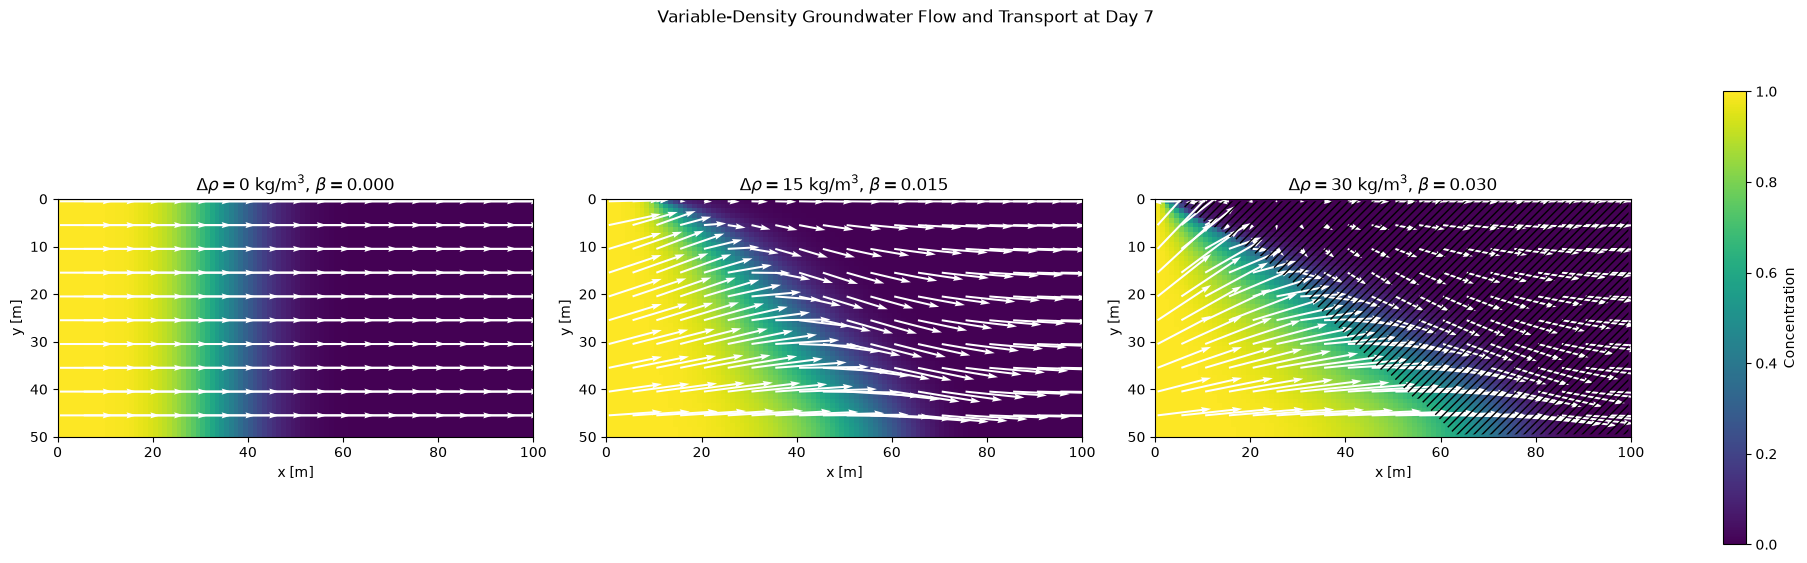

-----------------------------------------------------------------
   Delta rho         Beta           Max |Uy|            Max |U|
-----------------------------------------------------------------
         0.0       0.0000       2.091127e-17       1.666667e-05
        15.0       0.0150       6.136894e-06       2.978295e-05
        30.0       0.0300       1.848743e-05       3.764326e-05
-----------------------------------------------------------------


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags
from scipy.sparse.linalg import splu

# parameter
rho = 1000.0          # freshwater density [kg/m^3]
mu = 1e-3             # dynamic viscosity [Pa s]
g = 9.81              # gravitational acceleration [m/s^2]
k = 1e-10             # intrinsic permeability [m^2]
phi = 0.3             # porosity
D_diff = 1e-9         # molecular diffusion [m^2/s]
alpha = 1.0           # isotropic dispersivity [m]

Lx = 100.0
Ly = 50.0

nx = 100
ny = 50
nc = nx * ny

dx = Lx / nx
dy = Ly / ny

# Density differences to investigate
density_differences = [0, 15, 30]

xCells = np.arange(dx/2, Lx, dx)
yCells = np.arange(dy/2, Ly, dy)

xx, yy = np.meshgrid(xCells, yCells)

# Boundary conditions
uin = 0.1 / 100 / 60    # [m/s]
hR = 9.0                # [m]

day = 24 * 3600
t_end = 7 * day         # simulate until day 7

# homogeneous permeability field
Kmat = np.full((ny, nx), rho * g * k / mu)

# transmissibility matrix
K_har_x = 2.0 / (
    1.0 / Kmat[:, :-1] + 1.0 / Kmat[:, 1:]
)

K_har_y = 2.0 / (
    1.0 / Kmat[:-1, :] + 1.0 / Kmat[1:, :]
)

TLmat = np.full((ny, nx), np.nan)
TLmat[:, 0] = 0.0
TLmat[:, 1:] = (2.0 / dx) * dy * K_har_x

TRmat = np.full((ny, nx), np.nan)
TRmat[:, -1] = (2.0 / dx) * dy * Kmat[:, -1]
TRmat[:, :-1] = (2.0 / dx) * dy * K_har_x

TUmat = np.full((ny, nx), np.nan)
TUmat[0, :] = 0.0
TUmat[1:, :] = (2.0 / dy) * dx * K_har_y

TDmat = np.full((ny, nx), np.nan)
TDmat[-1, :] = 0.0
TDmat[:-1, :] = (2.0 / dy) * dx * K_har_y

# Flatten using Fortran ordering
TL = TLmat.flatten(order='F')
TR = TRmat.flatten(order='F')
TU = TUmat.flatten(order='F')
TD = TDmat.flatten(order='F')

TC = TL + TR + TU + TD

# Sparse transmissibility matrix
Tmat = (
    diags(TC, 0, shape=(nc, nc))
    + diags(-TL[ny:nc], -ny, shape=(nc, nc))
    + diags(-TU[1:nc], -1, shape=(nc, nc))
    + diags(-TD[:nc-1], 1, shape=(nc, nc))
    + diags(-TR[:nc-ny], ny, shape=(nc, nc))
).tocsc()

# Factorize once because permeability is constant
LU = splu(Tmat)

#variable-density flow solver
def solve_flow(Cmat, beta):

    # Concentration at internal vertical faces
    Cfy = 0.5 * (Cmat[:-1, :] + Cmat[1:, :])

    CfU = np.zeros((ny, nx))
    CfD = np.zeros((ny, nx))

    CfU[1:, :] = Cfy
    CfD[:-1, :] = Cfy

    # Right-hand side
    bmat = (
        TUmat * beta * CfU * dy
        - TDmat * beta * CfD * dy
    )

    bmat[:, 0] += uin * dy
    bmat[:, -1] += TRmat[:, -1] * hR

    b = bmat.flatten(order='F')

    # Solve hydraulic head
    h = LU.solve(b)
    hmat = h.reshape((ny, nx), order='F')

    # Hydraulic head differences
    dh_x = hmat[:, :-1] - hmat[:, 1:]
    dh_y = hmat[:-1, :] - hmat[1:, :]

    # Darcy velocities at faces
    UL = np.full((ny, nx), np.nan)
    UL[:, 0] = uin
    UL[:, 1:] = TLmat[:, 1:] / dy * dh_x

    UR = np.full((ny, nx), np.nan)
    UR[:, -1] = (
        TRmat[:, -1] / dy * (hmat[:, -1] - hR)
    )
    UR[:, :-1] = TRmat[:, :-1] / dy * dh_x

    UU = np.full((ny, nx), np.nan)
    UU[0, :] = 0.0
    UU[1:, :] = (
        TUmat[1:, :] / dx
        * (dh_y + beta * CfU[1:, :] * dy)
    )

    UD = np.full((ny, nx), np.nan)
    UD[-1, :] = 0.0
    UD[:-1, :] = (
        TDmat[:-1, :] / dx
        * (dh_y + beta * CfD[:-1, :] * dy)
    )

    # Cell-centered Darcy velocities
    Ux = 0.5 * (UL + UR)
    Uy = 0.5 * (UU + UD)

    # Pore velocity magnitude
    V_mag = np.sqrt(Ux**2 + Uy**2) / phi
    V_max = np.max(V_mag)

    return hmat, UL, UR, UU, UD, Ux, Uy, V_mag, V_max

#solute transport solver
def transport_step(Cmat, UL, UR, UU, UD, V_max, C_in):

    # Neighboring cell concentrations
    CL = np.full((ny, nx), np.nan)
    CR = np.full((ny, nx), np.nan)
    CU = np.full((ny, nx), np.nan)
    CD = np.full((ny, nx), np.nan)

    CL[:, 0] = C_in
    CL[:, 1:] = Cmat[:, :-1]

    # Zero-gradient outlet
    CR[:, -1] = Cmat[:, -1]
    CR[:, :-1] = Cmat[:, 1:]

    # No-flow top and bottom
    CU[0, :] = 0.0
    CU[1:, :] = Cmat[:-1, :]

    CD[-1, :] = 0.0
    CD[:-1, :] = Cmat[1:, :]

    # advection fluxes
    Fadv_L = np.full((ny, nx), np.nan)
    Fadv_R = np.full((ny, nx), np.nan)
    Fadv_U = np.full((ny, nx), np.nan)
    Fadv_D = np.full((ny, nx), np.nan)

    ind = UL >= 0
    Fadv_L[ind] = UL[ind] * CL[ind]
    Fadv_L[~ind] = UL[~ind] * Cmat[~ind]

    ind = UR >= 0
    Fadv_R[ind] = UR[ind] * Cmat[ind]
    Fadv_R[~ind] = UR[~ind] * CR[~ind]

    ind = UU >= 0
    Fadv_U[ind] = UU[ind] * CU[ind]
    Fadv_U[~ind] = UU[~ind] * Cmat[~ind]

    ind = UD >= 0
    Fadv_D[ind] = UD[ind] * Cmat[ind]
    Fadv_D[~ind] = UD[~ind] * CD[~ind]

    netFadv = (
        -Fadv_L * dy
        -Fadv_U * dx
        +Fadv_D * dx
        +Fadv_R * dy
    )

    # dispersive fluxes
    Dmat = D_diff + alpha * V_mag

    Dx_har = 2.0 / (
        1.0 / Dmat[:, :-1] + 1.0 / Dmat[:, 1:]
    )

    Dy_har = 2.0 / (
        1.0 / Dmat[:-1, :] + 1.0 / Dmat[1:, :]
    )

    DL = np.full((ny, nx), np.nan)
    DR = np.full((ny, nx), np.nan)
    DU = np.full((ny, nx), np.nan)
    DD = np.full((ny, nx), np.nan)

    # Left boundary
    DL[:, 0] = 2.0 * Dmat[:, 0]
    DL[:, 1:] = Dx_har

    # Right boundary
    DR[:, -1] = Dmat[:, -1]
    DR[:, :-1] = Dx_har

    # Top and bottom boundaries
    DU[0, :] = 0.0
    DU[1:, :] = Dy_har

    DD[-1, :] = 0.0
    DD[:-1, :] = Dy_har

    Fdis_L = phi * DL * (CL - Cmat) / dx
    Fdis_R = phi * DR * (Cmat - CR) / dx
    Fdis_U = phi * DU * (CU - Cmat) / dy
    Fdis_D = phi * DD * (Cmat - CD) / dy

    netFdis = (
        -Fdis_L * dy
        -Fdis_U * dx
        +Fdis_D * dx
        +Fdis_R * dy
    )

    # time step
    dt_adv = 0.1 * dx / V_max
    dt_dis = 0.1 * dx**2 / np.max(Dmat)

    dt = min(dt_adv, dt_dis)

    return netFadv + netFdis, dt

results = {}

for drho in density_differences:

    beta = drho / rho

    # Initial concentration
    Cmat = np.zeros((ny, nx))

    t = 0.0

    # Time loop
    while t < t_end - 1e-10:

        # Flow depends on the current concentration
        hmat, UL, UR, UU, UD, Ux, Uy, V_mag, V_max = (
            solve_flow(Cmat, beta)
        )

        # Injection concentration: first 10 days
        if t < 10 * day:
            C_in = 1.0
        else:
            C_in = 0.0

        # Calculate total transport flux
        netF, dt = transport_step(
            Cmat, UL, UR, UU, UD, V_max, C_in
        )

        # Ensure exact stopping at day 7
        dt = min(dt, t_end - t)

        # Advance concentration
        t += dt
        Cmat = Cmat - dt / (phi * dx * dy) * netF

    # Recalculate flow at the final day-7 concentration
    hmat, UL, UR, UU, UD, Ux, Uy, V_mag, V_max = (
        solve_flow(Cmat, beta)
    )

    # Darcy velocity magnitude
    U_magnitude = np.sqrt(Ux**2 + Uy**2)

    # Maximum velocities
    max_Uy = np.max(np.abs(Uy))
    max_U = np.max(U_magnitude)

    results[drho] = {
        'beta': beta,
        'C': Cmat.copy(),
        'h': hmat.copy(),
        'Ux': Ux.copy(),
        'Uy': Uy.copy(),
        'max_Uy': max_Uy,
        'max_U': max_U
    }

#plot concentration and velocity vectors
fig, axes = plt.subplots(1, 3, figsize=(18, 6), layout='constrained')

for ax, drho in zip(axes, density_differences):

    C = results[drho]['C']
    Ux = results[drho]['Ux']
    Uy = results[drho]['Uy']

    im = ax.imshow(
        C,
        origin='upper',
        aspect='equal',
        extent=[0, Lx, Ly, 0],
        vmin=0,
        vmax=1,
        cmap='viridis'
    )

    # Plot velocity vectors
    skip = 5

    ax.quiver(
        xx[::skip, ::skip],
        yy[::skip, ::skip],
        Ux[::skip, ::skip],
        Uy[::skip, ::skip],
        color='white',
        scale=0.00015
    )

    # Highlight upward-flow regions for delta rho = 30
    if drho == 30:
        ax.contourf(
            xx,
            yy,
            (Uy < 0).astype(float),
            levels=[0.5, 1.5],
            colors='none',
            hatches=['////']
        )

    ax.set_xlim(0, Lx)
    ax.set_ylim(Ly, 0)
    ax.set_xlabel('x [m]')
    ax.set_ylabel('y [m]')

    ax.set_title(
        rf'$\Delta\rho={drho}$ kg/m$^3$, '
        rf'$\beta={drho/rho:.3f}$'
    )

cbar = fig.colorbar(im, ax=axes, shrink=0.8)
cbar.set_label('Concentration')

plt.suptitle(
    'Variable-Density Groundwater Flow and Transport at Day 7'
)

plt.show()

# table of maximum velocities
print("-" * 65)
print(
    f"{'Delta rho':>12} {'Beta':>12} "
    f"{'Max |Uy|':>18} {'Max |U|':>18}"
)
print("-" * 65)

for drho in density_differences:

    r = results[drho]

    print(
        f"{drho:12.1f} "
        f"{r['beta']:12.4f} "
        f"{r['max_Uy']:18.6e} "
        f"{r['max_U']:18.6e}"
    )

print("-" * 65)
